In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

# Выбор задачи
Был выбран случайный лес из 2 лабы.

In [2]:
# Загрузка

DATA_PATH= "train.csv"
data = pd.read_csv(DATA_PATH, sep=",")
print(data.shape)
print("Типы признаков:")
print(data.dtypes.to_string())

(891, 9)
Типы признаков:
Id            int64
Pclass        int64
Sex             str
Age         float64
SibSp         int64
Parch         int64
Fare        float64
Embarked        str
Survived      int64


In [3]:
# Подготовка данных
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder 
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE=42
X = data.drop(columns=['Survived'])
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
skewed = ['Fare']
num_cols = ['Age', 'SibSp', 'Parch']
cat_cols = ['Sex', 'Pclass', 'Embarked']
preprocess = ColumnTransformer([
    ('num', Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median"))
        ]
            ), num_cols),
    ('cat', Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown='ignore'))
            ]), cat_cols),
    
])
random_forest = Pipeline(
    [("preprocess", preprocess),
      ("tree",
       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    )]
)

In [4]:
#baseline
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
baseline = Pipeline(
    [("preprocess", preprocess),
      ("tree",
       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, max_depth=10, min_samples_leaf=4, n_estimators=300)
    )]
)
scores = cross_validate(
    baseline, X_train, y_train, cv=cv,
    scoring="f1",
    return_train_score=True, n_jobs=-1
)
print(f"Среднее: {scores["test_score"].mean()}\nСтандартное отклонение {scores["test_score"].std()}")
print("F1 метрики")
print(scores["test_score"])

Среднее: 0.6966641841778621
Стандартное отклонение 0.036929903372152406
F1 метрики
[0.68085106 0.69387755 0.70212766 0.64646465 0.76      ]


# Гиперпараметры
n_estimators, max_depth, min_samples_leaf.
## n_estimators
Количество деревьев в случайном лесе.
Диапазон значений: 100 - 500.
При повышении параметра стабилизируется impurity, уменьшается переобучение, но увеличивается время обучения модели.
## max_depth
Максимальная глубина каждого дерева.
Диапазон значений: 2 - 16.
Слишком маленькая максимальная глубина приводит к underfitting, а слишком большая к overfitting.
## min_samples_leaf
Минимальное количество объектов в листе.
Диапазон значений - 2 - 32.
При росте параметра модель меньше переобучается. При слишком большом параметре происходит underfitting.

# Кросс-валидация
Я возьму 5 folds, это стандартное значение. 142 объекта уйдет на тест, остальное на обучение.
1. Зачем нужна кросс-валидация
Чтобы получить устойчивую оценку обобщения: каждое наблюдение побывает в тесте ровно один раз, а оценка не зависит от удачности одного разбиения.
2. Почему одного train/test недостаточно для подбора
Хуже обобщается. Разница в нескольких объектах хуже влияет на метрику.
3. Что будет при многократном подборе по test
Тест перестает быть независимым. Мы подстраиваемся под тест и получаем завышенную оценку.

In [18]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
import time
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
parameter_grid = {
    "tree__n_estimators": [100, 300, 500],
    "tree__max_depth": [None, 2, 4, 8, 16],
    "tree__min_samples_leaf": [2, 4, 8, 16, 32],
}
prev_time = time.perf_counter()
grid_search = GridSearchCV(
    random_forest, parameter_grid, cv=cv,
    scoring="f1",
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)
elapsed = time.perf_counter() - prev_time
r = grid_search.cv_results_
print("Лучшие гиперпараметры")
print(grid_search.best_params_)
print("Значение метрики")
print(grid_search.best_score_)
best_model = grid_search.best_estimator_
results = pd.DataFrame(grid_search.cv_results_)
results[[
    "params",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time"
]].sort_values("mean_test_score", ascending=False).head()
print(f"Количество проверенных комбинаций {len(r["params"])}")
print(f"Затрачено времени: {elapsed}")

/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread

Лучшие гиперпараметры
{'tree__max_depth': 4, 'tree__min_samples_leaf': 2, 'tree__n_estimators': 100}
Значение метрики
0.7191554578924368
Количество проверенных комбинаций 75
Затрачено времени: 32.58025899600034


In [ ]:
#random search
import time
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint
parameter_dist = {
    "tree__n_estimators": randint(100, 800),
    "tree__max_depth": randint(2, 16),
    "tree__min_samples_leaf": [None, 2, 4, 8, 16, 32],
}
random_search= RandomizedSearchCV(
    random_forest, parameter_dist,
    n_iter=60,                 # сколько конфигураций попробовать
    cv=cv,
    scoring="f1",
    random_state=RANDOM_STATE,
    n_jobs=-1, 
)
prev_time = time.perf_counter()
random_search.fit(X_train, y_train)
elapsed = time.perf_counter() - prev_time
r = random_search.cv_results_
print("Лучшие гиперпараметры")
print(random_search.best_params_)
print("Значение метрики")
print(random_search.best_score_)
best_model = random_search.best_estimator_
results = pd.DataFrame(random_search.cv_results_)
results[[
    "params",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time"
]].sort_values("mean_test_score", ascending=False).head()
print(f"Количество проверенных комбинаций {len(r["params"])}")
print(f"Затрачено времени: {elapsed}")

/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread

Лучшие гиперпараметры
{'tree__max_depth': 3, 'tree__min_samples_leaf': 2, 'tree__n_estimators': 655}
Значение метрики
0.7154057765752053
Количество проверенных комбинаций 60
Затрачено времени: 38.13781909699901


# Влияние гиперпараметров

## Схема исследования
Меняем по одному гиперпараметру, а остальные фиксируем на значениях из baseline:
`n_estimators=300`, `max_depth=10`, `min_samples_leaf=4`.
Метрика — F1 на той же 5-fold кросс-валидации, что и в baseline. На графиках показано среднее значение по фолдам и полоса ±1 стандартного отклонения.

In [9]:
BASELINE_PARAMS = {"n_estimators": 300, "max_depth": 10, "min_samples_leaf": 4}

# F1 baseline на тех же фолдах - для сравнения на графиках
baseline_cv = cross_validate(
    Pipeline([
        ("preprocess", preprocess),
        ("tree", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **BASELINE_PARAMS)),
    ]),
    X_train, y_train, cv=cv, scoring="f1", n_jobs=1,
)
F1_BASELINE = baseline_cv["test_score"].mean()
print(f"Baseline F1: {F1_BASELINE:.4f}")


def evaluate_hyperparameter(param_name, values):
    """Перебирает один гиперпараметр, остальные оставляет как в baseline."""
    rows = []
    for value in values:
        params = {**BASELINE_PARAMS, param_name: value}
        model = Pipeline([
            ("preprocess", preprocess),
            ("tree", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params)),
        ])
        cv_scores = cross_validate(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=1)
        rows.append({
            param_name: value,
            "mean_f1": cv_scores["test_score"].mean(),
            "std_f1": cv_scores["test_score"].std(),
        })
    return pd.DataFrame(rows)


def plot_hyperparameter(df, param_name, title):
    """График среднего F1 (с полосой ±1 std) в зависимости от одного гиперпараметра."""
    x = df[param_name].to_numpy()
    mean = df["mean_f1"].to_numpy()
    std = df["std_f1"].to_numpy()

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(x, mean, marker="o", color="tab:blue", label="F1 (5-fold CV, mean)")
    ax.fill_between(x, mean - std, mean + std, color="tab:blue", alpha=0.15, label="±1 std")
    ax.axhline(F1_BASELINE, color="tab:red", linestyle="--",
               label=f"baseline F1 = {F1_BASELINE:.3f}")

    best = int(np.argmax(mean))
    ax.scatter(x[best], mean[best], s=120, facecolors="none", edgecolors="tab:green",
               linewidths=2, zorder=5,
               label=f"max F1 = {mean[best]:.3f} при {param_name}={x[best]}")

    ax.set_title(title)
    ax.set_xlabel(param_name)
    ax.set_ylabel("F1")
    ax.set_xticks(x)
    low = min((mean - std).min(), F1_BASELINE)
    high = max((mean + std).max(), F1_BASELINE)
    ax.set_ylim(low - 0.02, high + 0.02)
    ax.legend(loc="best")
    fig.tight_layout()
    plt.show()

Baseline F1: 0.6967


### n_estimators
Количество деревьев в лесе. С ростом параметра средний F1 почти не меняется, немного уменьшается разброс f1 по foldам. Так как случайный лес усредняет результат нескольких деревьев, то логично, что чем больше количество деревьев, тем меньше дисперсия вероятности одного класса, тем меньше дисперсия f1.

 n_estimators  mean_f1  std_f1
          100   0.6984  0.0407
          200   0.6994  0.0362
          300   0.6967  0.0369
          400   0.6996  0.0367
          500   0.6981  0.0364


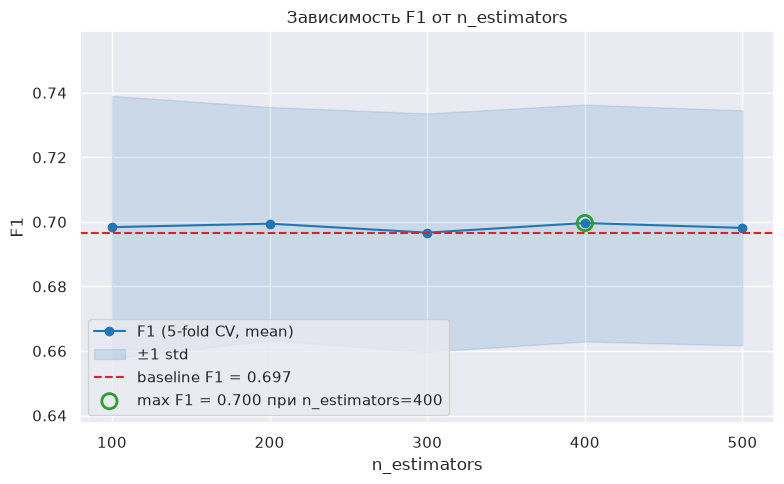

In [10]:
df_n_estimators = evaluate_hyperparameter("n_estimators", [100, 200, 300, 400, 500])
print(df_n_estimators.round(4).to_string(index=False))
plot_hyperparameter(df_n_estimators, "n_estimators", "Зависимость F1 от n_estimators")

### max_depth
Максимальная глубина дерева. Маленькая глубина ведёт к underfitting, слишком большая — к overfitting. Чем больше глубина дерева, тем больше развилок оно может сохранить и больше зависимостей в данных найти.
Модель переобучается после max_depth = 8.

 max_depth  mean_f1  std_f1
         2   0.7146  0.0307
         4   0.7146  0.0363
         6   0.7013  0.0404
         8   0.6953  0.0390
        10   0.6967  0.0369
        12   0.6996  0.0367
        14   0.6967  0.0369
        16   0.6967  0.0369


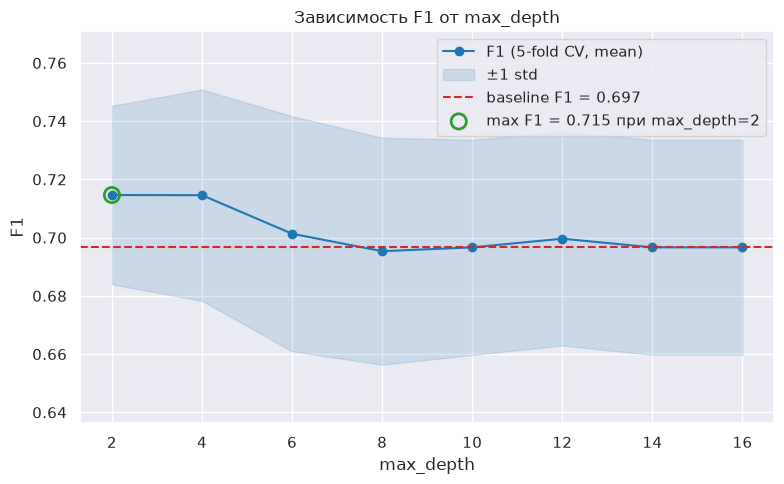

In [11]:
df_max_depth = evaluate_hyperparameter("max_depth", [2, 4, 6, 8, 10, 12, 14, 16])
print(df_max_depth.round(4).to_string(index=False))
plot_hyperparameter(df_max_depth, "max_depth", "Зависимость F1 от max_depth")

### min_samples_leaf
Минимальное число объектов в листе. Рост параметра сглаживает модель (снижает переобучение), но слишком большое значение даёт underfitting.
Недообучение наблюдается до min_samples_leaf=12. Небольшое переобучение после min_samples_leaf=40. Чем больше количество объектов в листьях, тем лучше правила в узлах дерева обобщают.

 min_samples_leaf  mean_f1  std_f1
                2   0.6947  0.0243
                4   0.6967  0.0369
                6   0.7102  0.0437
                8   0.6976  0.0469
               16   0.7024  0.0340
               32   0.7112  0.0283
               40   0.7050  0.0276
               50   0.7050  0.0276
               64   0.7050  0.0276


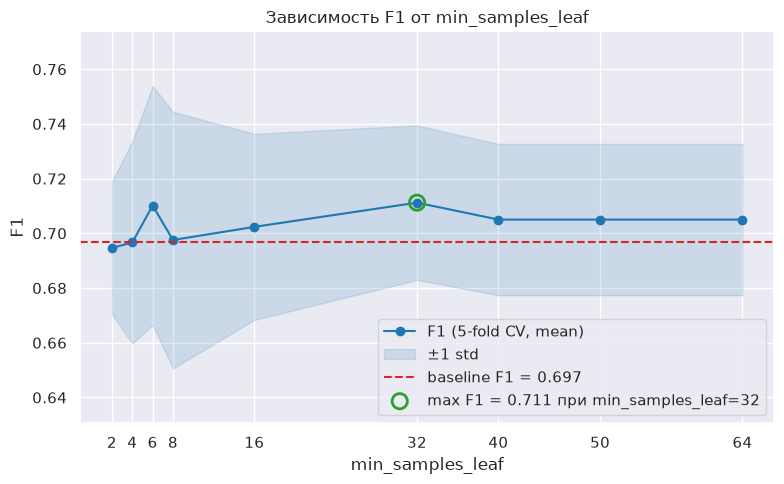

In [14]:
df_min_samples_leaf = evaluate_hyperparameter("min_samples_leaf", [2, 4, 6, 8, 16, 32, 40, 50, 64])
print(df_min_samples_leaf.round(4).to_string(index=False))
plot_hyperparameter(df_min_samples_leaf, "min_samples_leaf", "Зависимость F1 от min_samples_leaf")

# Финальная модель

## Сравнение baseline, Grid Search и Random Search
CV F1 — среднее по 5 фолдам на `train`, Test F1 — F1 на отложенной тестовой выборке (`X_test`), которая не участвовала в подборе гиперпараметров.

In [19]:
from sklearn.metrics import f1_score

# baseline обучаем на всем train: кросс-валидация выше использовала клоны модели
baseline.fit(X_train, y_train)

models = {
    "Baseline": (baseline, BASELINE_PARAMS, F1_BASELINE),
    "Grid Search": (
        grid_search.best_estimator_,
        {k.replace("tree__", ""): v for k, v in grid_search.best_params_.items()},
        grid_search.best_score_,
    ),
    "Random Search": (
        random_search.best_estimator_,
        {k.replace("tree__", ""): v for k, v in random_search.best_params_.items()},
        random_search.best_score_,
    ),
}

comparison = pd.DataFrame([
    {
        "Модель": name,
        "Лучшие гиперпараметры": params,
        "CV F1": cv_score,
        "Test F1": f1_score(y_test, model.predict(X_test)),
    }
    for name, (model, params, cv_score) in models.items()
]).set_index("Модель")

comparison.round(4)

,Лучшие гиперпараметры,CV F1,Test F1
Модель,,,
Baseline,"{'n_estimators': 300, 'max_depth': 10, 'min_sa...",0.6967,0.7934
Grid Search,"{'max_depth': 4, 'min_samples_leaf': 2, 'n_est...",0.7192,0.7833
Random Search,"{'max_depth': 3, 'min_samples_leaf': 2, 'n_est...",0.7154,0.7627


## Результаты по фолдам
F1 на каждой из 5 валидационных фолдов (те же разбиения, что и при подборе), плюс среднее и стандартное отклонение.

In [22]:
fold_models = {
    "Baseline": baseline,
    "Grid Search": grid_search.best_estimator_,
    "Random Search": random_search.best_estimator_,
}

fold_scores = pd.DataFrame({
    name: cross_validate(model, X_train, y_train, cv=cv, scoring="f1")["test_score"]
    for name, model in fold_models.items()
})
fold_scores.index = [f"fold {i}" for i in range(1, len(fold_scores) + 1)]

mean_row = fold_scores.mean()
std_row = fold_scores.std()
fold_scores.loc["mean"] = mean_row
fold_scores.loc["std"] = std_row

print(fold_scores.round(4).to_string())

        Baseline  Grid Search  Random Search
fold 1    0.6809       0.7021         0.6875
fold 2    0.6939       0.7010         0.7200
fold 3    0.7021       0.7253         0.7097
fold 4    0.6465       0.6981         0.6789
fold 5    0.7600       0.7692         0.7810
mean      0.6967       0.7192         0.7154
std       0.0413       0.0300         0.0402


## Анализ результатов
Модели, для которых подбирали гиперпараметры, лучше показали себя на CV F1, но хуже на тестовой выборке. Возможно нам просто повезло с тестовой выборкой, потому что на CV у baseline решения довольно большой разброс по F1. 0.68 - худший результат и 0.76 - лучший.
Grid Search дал самую стабильную модель.
Random Search дал менее стабильную модель.